# 7. Design how a bunny hangs under gravity

Hang the tetrahedral bunny by its ear tips. Prescribe a permanent stretch
in the band just below the clamps and fit it so the lowest point of the
bunny under gravity reaches $y=-0.015$.

Use Neo-Hookean elasticity with fixed $(\lambda,\mu)=(2,3)$ and vary the
prescribed plastic state $F_p$. The material evaluates the elastic part
$F_e=FF_p^{-1}$. Each trial solves gravity equilibrium and measures the
lowest deformed vertex in the entire mesh.

In [1]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sp
import torch
from matplotlib.collections import PolyCollection
%matplotlib inline
from litepgo import dof, energy, fem, mesh, solver, tbb_thread_limit
from litepgo.torch import response

torch.set_num_threads(1)
asset_dir = next(folder for folder in (Path('.'), Path('assets'), Path('../../assets'))
                 if (folder / 'bunny-tet.veg').is_file())
bunny = mesh.read_veg(asset_dir / 'bunny-tet.veg')

## Clamp the ear tips and mark the plastic band

The mesh's vertical coordinate is $y$. For this bunny, the plane
$x=-0.058$ separates the two ear tips. Measure depth below each tip in
units of the whole bunny's rest height. Clamp all three displacement
components of the vertices whose depth is at most 2% of the full rest height.

Select the tetrahedra whose rest centroids lie between 2% and 9% below
their respective tips. Both patches of this plastic band share one set
of parameters. All cells remain in the solve because the body can move.

In [2]:
X, topology = bunny.positions, bunny.topology
cells = topology.cells
ear_split = -.058
y = X[:, 1]
rest_height = np.ptp(y)
tall_side = X[:, 0] > ear_split
tall_tip_y, short_tip_y = y[tall_side].max(), y[~tall_side].max()

def tip_depth_fraction(points):
    tip_y = np.where(points[:, 0] > ear_split, tall_tip_y, short_tip_y)
    return (tip_y - points[:, 1]) / rest_height

clamped = tip_depth_fraction(X) <= .02
centroids = X[cells].mean(axis=1)
depth = tip_depth_fraction(centroids)
band = (.02 < depth) & (depth <= .09)
assert clamped[tall_side].any() and clamped[~tall_side].any() and band.any()
fixed = dof.DofReduction(X.size, np.flatnonzero(np.repeat(clamped, 3)).tolist())
mapping = dof.VertexDofMap(topology, 3)
basis = fem.TetP1Basis
key = (fem.NeoHookean, basis, fem.TetCentroidQuadrature)
geometry = [fem.InterpolatedResponse[basis](mapping.gather(e, X.ravel()))
            for e in range(topology.num_cells)]
theta = [energy.ConstantResponse(3, np.array([2., 3.]))] * topology.num_cells

print(f'Clamped vertices {clamped.sum()}; plastic tetrahedra {band.sum()}')

Clamped vertices 24; plastic tetrahedra 514


## Let the body hang under a fixed gravity load

Use unit density in the reference mesh. Each tetrahedron contributes a
quarter of its mass to each of its vertices. Apply a downward force
$m_i g$ at vertex $i$, using $g=0.1$ in mesh units. These reference
masses give the same gravity force for every trial $F_p$.

The total potential adds the elastic energy to $-f^\mathsf{T}u$.
First solve with $F_p=I$ to get the hanging shape before design. Use
its displacement to start the first solve with a plastic stretch.

In [3]:
rest_tets = X[cells]
tet_volumes = np.abs(np.linalg.det(rest_tets[:, 1:] - rest_tets[:, :1])) / 6
vertex_mass = np.zeros(len(X))
np.add.at(vertex_mass, cells.ravel(), np.repeat(tet_volumes / 4, 4))
g = .1
force = np.zeros_like(X)
force[:, 1] = -g * vertex_mass
gravity = energy.QuadraticEnergy(sp.csc_matrix((X.size, X.size)), -force.ravel())

np.testing.assert_allclose(vertex_mass.sum(), tet_volumes.sum())
np.testing.assert_allclose(force[:, 1].sum(), -g * tet_volumes.sum())

## Map a vertical stretch into the band

In the band, set $F_p=\operatorname{diag}(e^a,e^b,e^c)$. Positive $b$
increases the plastic rest length along $y$. Use only $b$ for the main
design, with $a=c=0$. The plastic volume ratio inside the band is
then $\det F_p=e^b$. Outside the band use $F_p=I$.

The main fit first expands $b$ into $(0,b,0)$.
`LogDiagonalFpResponse` converts the three log stretches into nine
column-major entries of the band's $F_p$. The energy assigns this
matrix to each band cell. For the adjoint, `band_to_elements` copies
the same entries into the corresponding slots of the force response
and supplies the identity to cells outside the band.

With $b=0$, the lowest point under gravity is about $-0.00284$. A scan
put the target $-0.015$ near $b=0.8$, so use that trial to warm-start
Newton during the fit. The before-design plot uses $b=0$.

In [4]:
identity = np.eye(3).ravel(order='F')
identity_field = energy.ConstantResponse(3, identity)
band_to_elements = energy.AffineResponse(
    sp.kron(band[:, None].astype(float), sp.eye(9), format='csc'),
    ((~band)[:, None] * identity).ravel(),
)
physical_map = dof.ElementDofMap(topology, 9)

newton_options = solver.NewtonOptions(gradient_tolerance=1e-10, max_iterations=60)

def total_energy(active_fp):
    active_field = energy.ConstantResponse(3, active_fp)
    fields = [active_field if active else identity_field for active in band]
    elastic = fem.VolumetricFemEnergy[key](mapping, geometry, fields, theta)
    return energy.WeightedSumEnergy([(elastic, 1.), (gravity, 1.)])

with tbb_thread_limit(4):
    baseline = solver.newton_solve(total_energy(identity), fixed, np.zeros(X.size), newton_options)
assert baseline.status == solver.NewtonStatus.Converged

def make_equilibrium(band_fp, initial):
    plastic = energy.ComposedResponse(band_to_elements, band_fp)

    def make_energy(p):
        return total_energy(band_fp.eval_value(p))

    def make_response(u):
        force_fp = fem.VolumetricFemForceFpResponse[key](physical_map, mapping, geometry, u, theta)
        return energy.ComposedResponse(force_fp, plastic)

    eq = solver.StaticEquilibriumResponse(
        band_fp.num_inputs, fixed, initial, newton_options, make_energy, make_response,
    )
    return eq, make_energy

log_to_fp = fem.LogDiagonalFpResponse(3)
expand_b = energy.AffineResponse(np.array([[0.], [1.], [0.]]))
b_to_fp = energy.ComposedResponse(log_to_fp, expand_b)

target_height = -.015
start_b = .8
with tbb_thread_limit(4):
    start_fp = b_to_fp.eval_value(np.array([start_b]))
    start_state = solver.newton_solve(total_energy(start_fp), fixed, baseline.x, newton_options)
assert start_state.status == solver.NewtonStatus.Converged
equilibrium, make_energy = make_equilibrium(b_to_fp, start_state.x)

## Fit the lowest point under gravity

For trial parameters $p$, let $u^*(p)$ be the displacement returned by
`response(equilibrium, p)`. The observed height is

$$H(p)=\min_i\{X_{i,y}+u^*_{i,y}(p)\}.$$

The minimum follows whichever vertex is lowest at that trial. Near a
state with a unique lowest vertex, the derivative follows that vertex.
The displacement vector is ordered $x,y,z$ per vertex, so `u[1::3]`
selects the vertical component. Check the adjoint against two
equilibria re-solved around the starting value of $b$.

Minimize $L(p)=\tfrac12[(H(p)-H_{\rm target})/10^{-3}]^2$. L-BFGS uses
$q=p/0.1$, so a unit step in $q$ changes the log stretch by $0.1$.

In [5]:
height_scale = .001
rest_y = torch.from_numpy(y.copy())

def lowest_y(u):
    return (rest_y + u[1::3]).min()

b_start = torch.tensor([start_b], dtype=torch.float64, requires_grad=True)
with tbb_thread_limit(4):
    adjoint, = torch.autograd.grad(lowest_y(response(equilibrium, b_start)), b_start)
    h = .002
    plus = lowest_y(response(equilibrium, b_start.detach() + h))
    minus = lowest_y(response(equilibrium, b_start.detach() - h))
finite_difference = (plus - minus) / (2 * h)
torch.testing.assert_close(adjoint[0], finite_difference, rtol=3e-3, atol=2e-7)
print(f'Height derivative, adjoint / finite difference: {adjoint.item():.8g} / {finite_difference.item():.8g}')

Height derivative, adjoint / finite difference: -0.020639338 / -0.020653413


In [6]:
def fit(equilibrium, start):
    q = (torch.tensor(start, dtype=torch.float64) / .1).requires_grad_()
    optimizer = torch.optim.LBFGS(
        [q], max_iter=12, tolerance_grad=1e-9, tolerance_change=1e-12,
        line_search_fn='strong_wolfe',
    )

    def closure():
        optimizer.zero_grad()
        u = response(equilibrium, .1 * q)
        loss = .5 * ((lowest_y(u) - target_height) / height_scale).square()
        loss.backward()
        return loss

    optimizer.step(closure)
    return .1 * q.detach()

with tbb_thread_limit(4):
    fitted_b = fit(equilibrium, [start_b])
    fitted_u = response(equilibrium, fitted_b)
    residual = make_energy(fitted_b.numpy()).eval_gradient(fitted_u.numpy())[fixed.free_dofs]

initial_height = lowest_y(torch.from_numpy(baseline.x.copy())).item()
fitted_height = lowest_y(fitted_u).item()
assert abs(fitted_height - target_height) < 1e-7
assert np.linalg.norm(residual) < 1e-8
print(f'Fitted b {fitted_b.item():.8f} (vertical plastic stretch {fitted_b.exp().item():.8f})')
print(f'Lowest point under gravity {initial_height:.9f} → {fitted_height:.9f}')
print(f'Target height {target_height:.9f}; error {abs(fitted_height - target_height):.2e}')
print(f'Free equilibrium residual norm {np.linalg.norm(residual):.2e}')

Fitted b 0.82756538 (vertical plastic stretch 2.28774216)
Lowest point under gravity -0.002836820 → -0.015000000
Target height -0.015000000; error 1.66e-12
Free equilibrium residual norm 4.72e-10


## Compare the two shapes under the same gravity

Both overviews use the same coordinates and scale. Orange faces mark the
surface of the plastic band, dark dots mark the clamps, and a star marks
the lowest vertex in each equilibrium. The close-up overlays the
two lower-body silhouettes at their actual positions so the drop to the
dashed target line is visible.

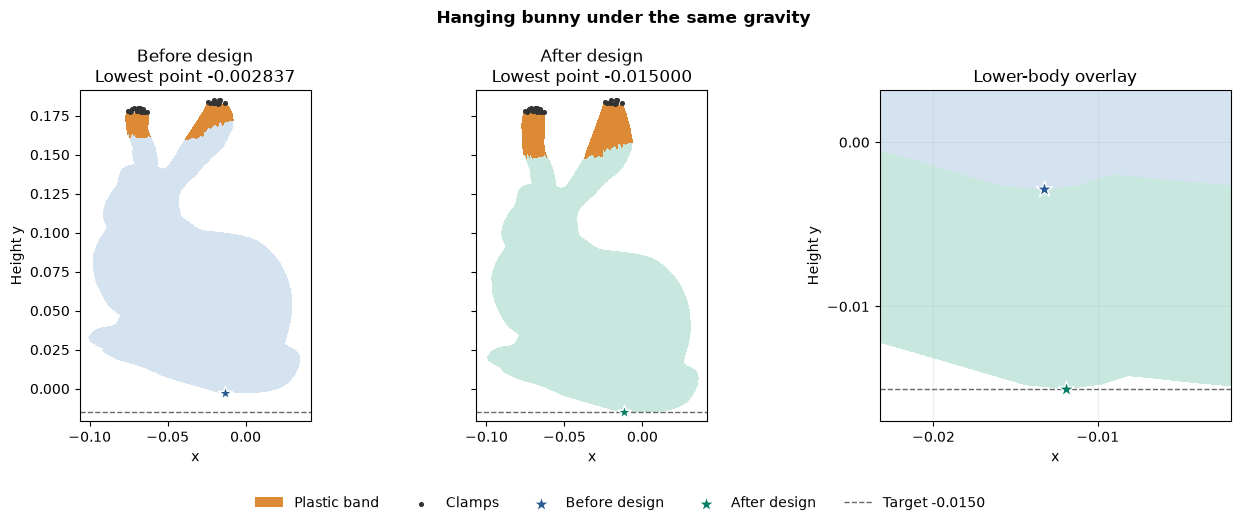

In [7]:
surface = mesh.extract_surface_with_vertices(bunny)
faces = np.asarray(surface.vertices)[surface.mesh.topology.cells]
# Match faces by vertex ID regardless of their orientation.
band_faces = {tuple(sorted(face)) for cell in cells[band] for face in combinations(cell, 3)}
surface_band = np.array([tuple(sorted(face)) in band_faces for face in faces])
assert surface_band.any()

before = X + baseline.x.reshape(-1, 3)
after = X + fitted_u.numpy().reshape(-1, 3)
states = [
    ('Before design', before, '#285b91', '#d5e2f0'),
    ('After design', after, '#087d68', '#c8e7df'),
]
extent = np.vstack((before[:, :2], after[:, :2]))
lo, hi = extent.min(axis=0) - .006, extent.max(axis=0) + .006

fig, (before_ax, after_ax, detail) = plt.subplots(
    1, 3, figsize=(12.6, 5.2), width_ratios=(1, 1, 1), layout='constrained',
)
fig.suptitle('Hanging bunny under the same gravity', fontweight='bold')
fig.get_layout_engine().set(h_pad=.10)
lowest = []
for ax, (label, positions, color, fill) in zip((before_ax, after_ax), states):
    xy = positions[:, :2]
    point = xy[xy[:, 1].argmin()]
    lowest.append(point)
    ax.add_collection(PolyCollection(
        xy[faces], facecolors=fill, edgecolors='none', antialiaseds=False,
    ))
    ax.add_collection(PolyCollection(
        xy[faces[surface_band]], facecolors='#dc8a36', edgecolors='none',
        antialiaseds=False, label='Plastic band',
    ))
    ax.scatter(*xy[clamped].T, color='0.2', s=7, zorder=3, label='Clamps')
    ax.axhline(target_height, color='0.4', linestyle='--', linewidth=1)
    ax.scatter(*point, s=110, marker='*', color=color, edgecolors='white', zorder=4)
    ax.set(title=f'{label}\nLowest point {point[1]:.6f}', xlabel='x',
           xlim=(lo[0], hi[0]), ylim=(lo[1], hi[1]), aspect='equal')
    ax.locator_params(axis='x', nbins=5)
    detail.scatter(*point, s=145, marker='*', color=color, edgecolors='white',
                   label=label, zorder=4)

before_ax.set_ylabel('Height y')
after_ax.tick_params(labelleft=False)
for _, positions, _, fill in reversed(states):
    detail.add_collection(PolyCollection(
        positions[:, :2][faces], facecolors=fill, edgecolors='none', antialiaseds=False,
    ))
detail.axhline(target_height, color='0.4', linestyle='--', linewidth=1,
               label=f'Target {target_height:.4f}')
points = np.array(lowest)
detail.set(title='Lower-body overlay', xlabel='x', ylabel='Height y', aspect='equal',
           xlim=(points[:, 0].min() - .010, points[:, 0].max() + .010),
           ylim=(min(points[:, 1].min(), target_height) - .002, points[:, 1].max() + .006))
detail.ticklabel_format(style='plain', useOffset=False)
detail.locator_params(nbins=4)
detail.grid(alpha=.2)
band_handles, band_labels = before_ax.get_legend_handles_labels()
point_handles, point_labels = detail.get_legend_handles_labels()
fig.legend(band_handles + point_handles, band_labels + point_labels,
           loc='outside lower center', ncols=5, frameon=False)
plt.show()

## Try it

Let all three log stretches $a,b,c$ vary in the same band. Start both
fits at the fitted $b$, with different $a$ and $c$. Match the lowest
point under the same gravity. Do the two states agree on the three stretches?
Compare how far apart their shapes are even though both meet the height
target.

In [8]:
full_equilibrium, full_energy = make_equilibrium(log_to_fp, fitted_u.numpy())
fitted_parameters, fitted_positions = [], []
with tbb_thread_limit(4):
    for a, c in ((.08, -.06), (-.06, .08)):
        start = [a, fitted_b.item(), c]
        parameters = fit(full_equilibrium, start)
        u = response(full_equilibrium, parameters)
        height = lowest_y(u).item()
        residual = full_energy(parameters.numpy()).eval_gradient(u.numpy())[fixed.free_dofs]
        assert abs(height - target_height) < 1e-7
        assert np.linalg.norm(residual) < 1e-8
        fitted_parameters.append(parameters.numpy())
        fitted_positions.append(X + u.numpy().reshape(-1, 3))
        print(f'Fitted (a, b, c) {parameters.numpy().round(6)}; lowest point {height:.9f}')

assert np.linalg.norm(fitted_parameters[0] - fitted_parameters[1]) > .001
difference = np.linalg.norm(fitted_positions[0] - fitted_positions[1], axis=1)
print(f'Maximum distance between corresponding vertices {difference.max():.6g}')

Fitted (a, b, c) [ 0.078857  0.821214 -0.060755]; lowest point -0.015000000
Fitted (a, b, c) [-0.060015  0.827463  0.079988]; lowest point -0.015000000
Maximum distance between corresponding vertices 0.00549112
